<a href="https://colab.research.google.com/github/Ved0705/VedSomeshLawand/blob/main/VedSomeshLawand.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option('display.max_columns', None)

In [13]:
# Upload the dataset

from google.colab import files

uploaded = files.upload()

Saving KosteckiDillon.csv to KosteckiDillon (1).csv


In [14]:
# Load the dataset into a DataFrame

df = pd.read_csv("KosteckiDillon.csv")

# Display the first five rows
df.head()

,rownames,id,time,dos,hatype,age,airq,medication,headache,sex
0,1,1,-11,753,Aura,30,9.0,continuing,yes,female
1,2,1,-10,754,Aura,30,7.0,continuing,yes,female
2,3,1,-9,755,Aura,30,10.0,continuing,yes,female
3,4,1,-8,756,Aura,30,13.0,continuing,yes,female
4,5,1,-7,757,Aura,30,18.0,continuing,yes,female


In [15]:
# Display the shape of the dataset

print("Shape of the dataset:", df.shape)

# Display column names

print("\nColumn Names:")
print(df.columns)

# Display dataset information

print("\nDataset Information:")
df.info()

Shape of the dataset: (4152, 10)

Column Names:
Index(['rownames', 'id', 'time', 'dos', 'hatype', 'age', 'airq', 'medication',
       'headache', 'sex'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4152 entries, 0 to 4151
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   rownames    4152 non-null   int64  
 1   id          4152 non-null   int64  
 2   time        4152 non-null   int64  
 3   dos         4152 non-null   int64  
 4   hatype      4152 non-null   object 
 5   age         4152 non-null   int64  
 6   airq        4152 non-null   float64
 7   medication  4152 non-null   object 
 8   headache    4152 non-null   object 
 9   sex         4152 non-null   object 
dtypes: float64(1), int64(5), object(4)
memory usage: 324.5+ KB


In [16]:
# Display statistical summary of numerical columns

df.describe()

,rownames,id,time,dos,age,airq
count,4152.000000,4152.000000,4152.000000,4152.000000,4152.000000,4152.000000
mean,2076.500000,66.386802,15.455684,646.705925,42.363921,24.826012
std,1198.723488,39.121812,21.737211,335.770123,11.201244,9.514274
min,1.000000,1.000000,-29.000000,98.000000,18.000000,3.000000
25%,1038.750000,33.000000,3.000000,384.000000,33.000000,18.000000
50%,2076.500000,67.000000,12.000000,623.000000,44.000000,24.000000
75%,3114.250000,100.000000,24.000000,950.000000,50.000000,29.000000
max,4152.000000,133.000000,99.000000,1239.000000,66.000000,73.000000


In [17]:
# Display summary of categorical columns

df.describe(include='object')

,hatype,medication,headache,sex
count,4152,4152,4152,4152
unique,3,3,2,2
top,No Aura,continuing,yes,female
freq,1985,2386,2666,3545


In [18]:
# Display the data type of each column

df.dtypes

,0
rownames,int64
id,int64
time,int64
dos,int64
hatype,object
age,int64
airq,float64
medication,object
headache,object
sex,object


In [19]:
# Check for missing values in each column

df.isnull().sum()

,0
rownames,0
id,0
time,0
dos,0
hatype,0
age,0
airq,0
medication,0
headache,0
sex,0


In [21]:
# Handle missing values

if df.isnull().sum().sum() == 0:
    print("The dataset does not contain any missing values.")
else:
    df = df.dropna()
    print("Missing values have been removed.")

The dataset does not contain any missing values.


In [22]:
# Check for duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [23]:
# Remove duplicate rows if any exist

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (4152, 10)


In [24]:
# Remove leading and trailing spaces from column names

df.columns = df.columns.str.strip()

# Display updated column names

print(df.columns)

Index(['rownames', 'id', 'time', 'dos', 'hatype', 'age', 'airq', 'medication',
       'headache', 'sex'],
      dtype='object')


In [25]:
# Convert categorical columns to category datatype

categorical_columns = ['hatype', 'medication', 'headache', 'sex']

for column in categorical_columns:
    df[column] = df[column].astype('category')

# Display updated data types

df.dtypes

,0
rownames,int64
id,int64
time,int64
dos,int64
hatype,category
age,int64
airq,float64
medication,category
headache,category
sex,category


In [26]:
# Display the first five rows after cleaning and transformation

df.head()

,rownames,id,time,dos,hatype,age,airq,medication,headache,sex
0,1,1,-11,753,Aura,30,9.0,continuing,yes,female
1,2,1,-10,754,Aura,30,7.0,continuing,yes,female
2,3,1,-9,755,Aura,30,10.0,continuing,yes,female
3,4,1,-8,756,Aura,30,13.0,continuing,yes,female
4,5,1,-7,757,Aura,30,18.0,continuing,yes,female


In [27]:
# Import visualization libraries

import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style

sns.set_style("whitegrid")

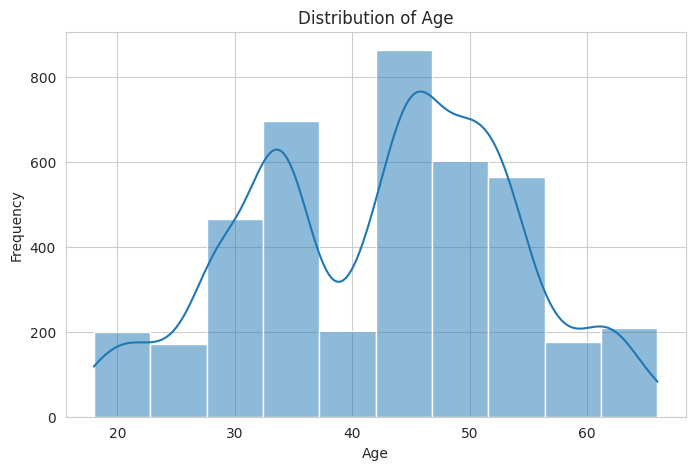

In [28]:
# Univariate Analysis - Distribution of Age

plt.figure(figsize=(8,5))
sns.histplot(df['age'], bins=10, kde=True)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

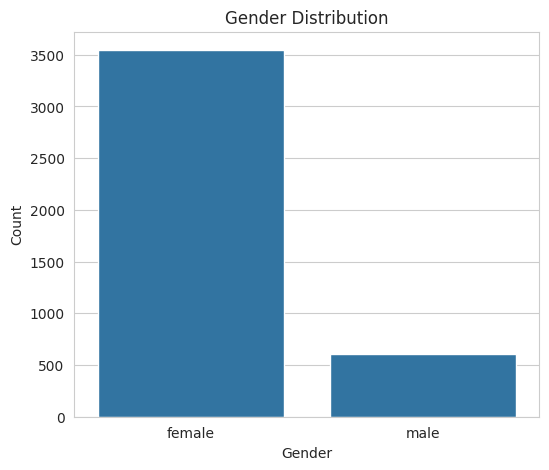

In [29]:
# Univariate Analysis - Distribution of Gender

plt.figure(figsize=(6,5))
sns.countplot(x='sex', data=df)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

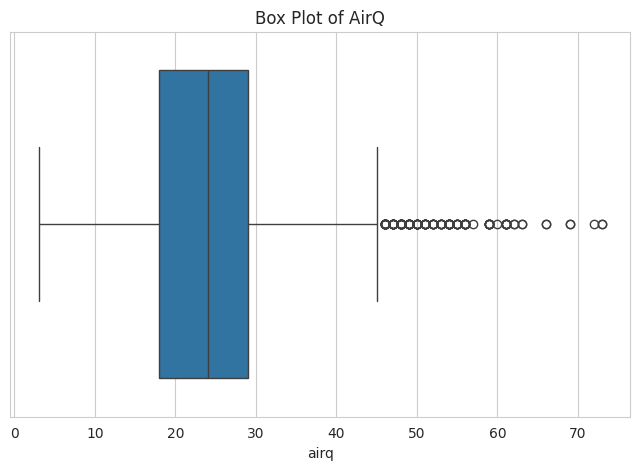

In [30]:
# Univariate Analysis - AirQ Distribution

plt.figure(figsize=(8,5))
sns.boxplot(x=df['airq'])

plt.title("Box Plot of AirQ")

plt.show()

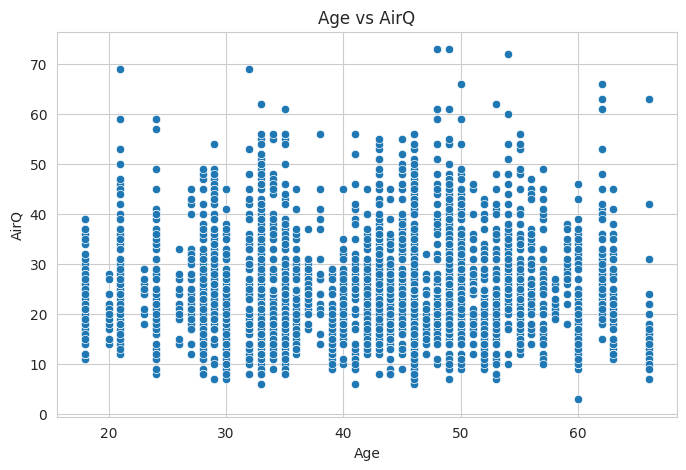

In [31]:
# Bivariate Analysis - Age vs AirQ

plt.figure(figsize=(8,5))
sns.scatterplot(x='age', y='airq', data=df)

plt.title("Age vs AirQ")
plt.xlabel("Age")
plt.ylabel("AirQ")

plt.show()

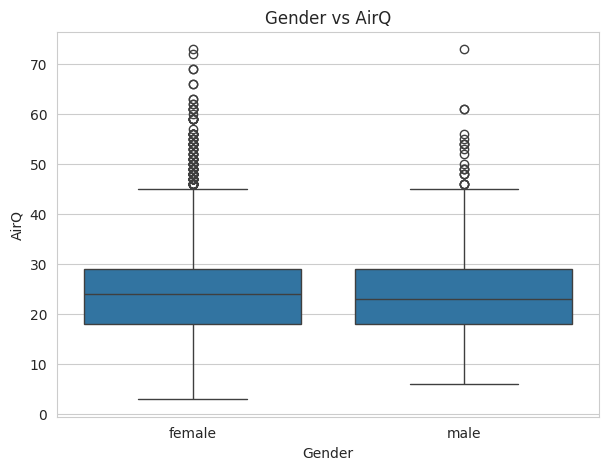

In [32]:
# Bivariate Analysis - Gender vs AirQ

plt.figure(figsize=(7,5))
sns.boxplot(x='sex', y='airq', data=df)

plt.title("Gender vs AirQ")
plt.xlabel("Gender")
plt.ylabel("AirQ")

plt.show()

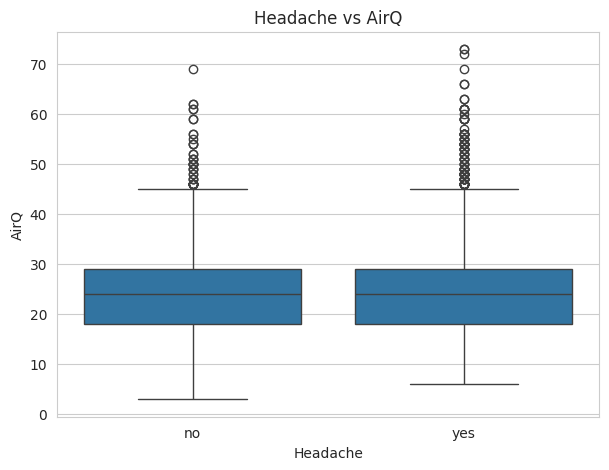

In [33]:
# Bivariate Analysis - Headache vs AirQ

plt.figure(figsize=(7,5))
sns.boxplot(x='headache', y='airq', data=df)

plt.title("Headache vs AirQ")
plt.xlabel("Headache")
plt.ylabel("AirQ")

plt.show()

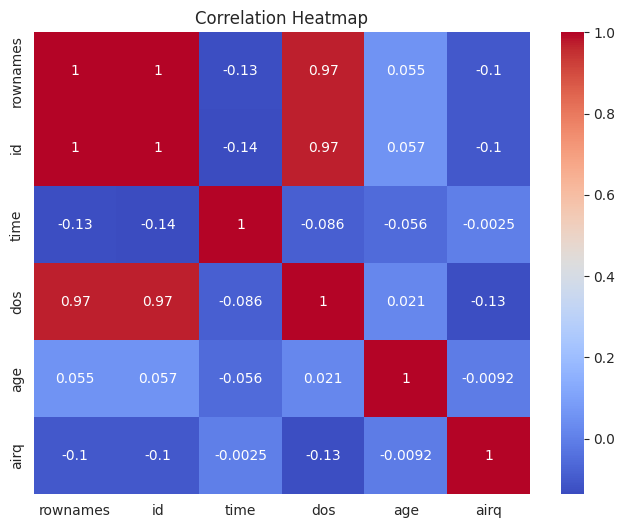

In [34]:
# Multivariate Analysis - Correlation Heatmap

plt.figure(figsize=(8,6))

numeric_df = df.select_dtypes(include=['number'])

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

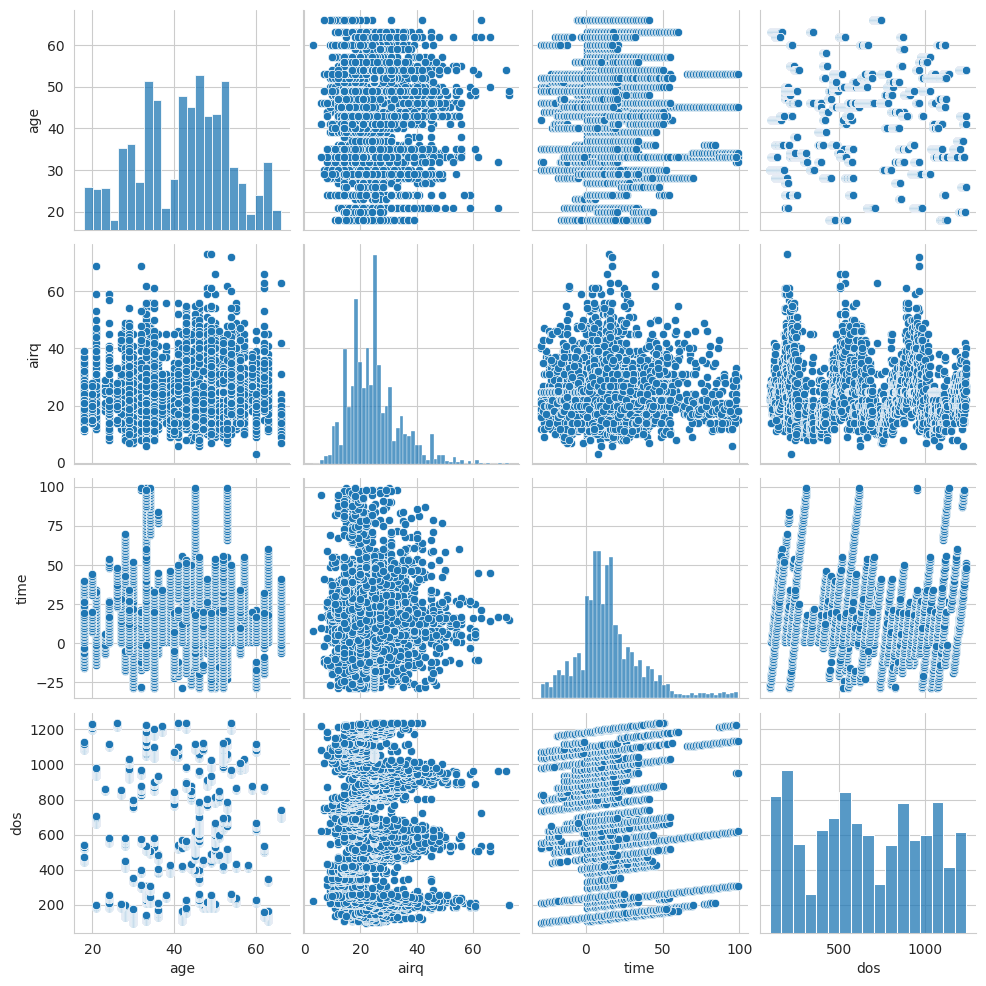

In [35]:
# Multivariate Analysis - Pair Plot

sns.pairplot(df[['age', 'airq', 'time', 'dos']], diag_kind='hist')

plt.show()

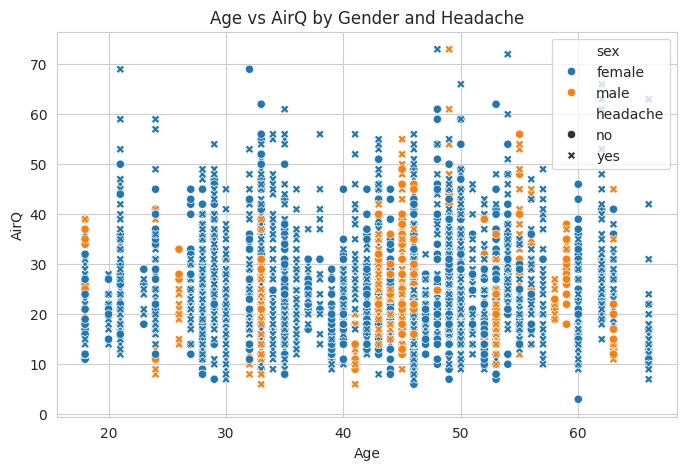

In [36]:
# Multivariate Analysis - Age vs AirQ grouped by Gender

plt.figure(figsize=(8,5))

sns.scatterplot(
    x='age',
    y='airq',
    hue='sex',
    style='headache',
    data=df
)

plt.title("Age vs AirQ by Gender and Headache")
plt.xlabel("Age")
plt.ylabel("AirQ")

plt.show()

In [37]:
# Conclusion

print("EDA Phase 1 Completed Successfully.")

print("\nKey Observations:")
print("1. The dataset contains no missing values.")
print("2. Duplicate rows were checked and removed if present.")
print("3. Categorical columns were transformed into category data type.")
print("4. Univariate, bivariate, and multivariate analyses were performed.")
print("5. Various visualizations helped understand the distribution and relationships among variables.")

EDA Phase 1 Completed Successfully.

Key Observations:
1. The dataset contains no missing values.
2. Duplicate rows were checked and removed if present.
3. Categorical columns were transformed into category data type.
4. Univariate, bivariate, and multivariate analyses were performed.
5. Various visualizations helped understand the distribution and relationships among variables.
